---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 5. Kerr quasinormal modes in LIGO noise

This page was generated from [`notebooks/gw/05_ringdown_kerr.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/05_ringdown_kerr.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/05_ringdown_kerr.py`.

Notebook 4 fitted a damped sinusoid with a free frequency and damping rate. In general
relativity the remnant of a binary merger is a Kerr black hole, and the frequency and damping
rate of every quasinormal mode are fixed by its mass $M$ and dimensionless spin $\chi$. A
*Kerr fit* samples $M$ and $\chi$ instead of the frequencies, and so tests whether several
modes agree on one black hole.

ringdown's GW150914 example fits the fundamental mode $(\ell, m, n) = (2, 2, 0)$ and its
first overtone $(2, 2, 1)$ to the Hanford and Livingston data, starting at the peak of the
signal. This notebook does the same on simulated data: the same two modes, priors, segment
length and antenna patterns, in two detectors with the noise of Advanced LIGO at design
sensitivity. Since the truth is known, we can check what the fit recovers.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

from dataclasses import dataclass

import astroinfer as ai
import jax.numpy as jnp
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import scipy.linalg
from astroinfer import MeasurementProcess, batched_method, parameter, parameter_dataclass
from astroinfer.display import html_value
from jax.scipy.linalg import solve_triangular
from numpyro.distributions import constraints

# The colors of tutorials/_style.py: posterior, prior, data and truth.
POSTERIOR, PRIOR, DATA, TRUTH = "#418FC5", "#eb6834", "#1baf7a", "#17243D"

T_MSUN = 4.925491025543576e-06  # G M_sun / c^3, in seconds
STRAIN_UNIT = 1e-21             # strain is measured in units of 1e-21 throughout
MODES = ("220", "221")

## The Kerr spectrum

For a Kerr black hole, the dimensionless frequency $M\omega$ and the quality factor
$Q = \pi f\tau$ of each mode depend on the spin alone. Berti, Cardoso and Will (2006, Table
VIII) fit them as

$$
M\omega = f_1 + f_2(1-\chi)^{f_3},\qquad Q = q_1 + q_2(1-\chi)^{q_3},
$$

from which $f = M\omega/(2\pi M)$, with $M$ in seconds, and $\gamma = 1/\tau = \pi f/Q$.
ringdown uses a longer series fitted to the `qnm` package instead. The data here are simulated
with the same fits that the analysis uses, so their small errors do not bias the result. The
fits are JAX functions of $M$ and $\chi$, so NUTS can take their gradient.

In [3]:
def kerr_qnms(M, chi):
    """Frequencies [Hz] and damping rates [1/s] of the 220 and 221 modes of a Kerr black hole.

    M is the detector-frame mass in solar masses and chi the dimensionless spin.
    """
    # Berti, Cardoso & Will (2006), Table VIII: (f1, f2, f3) and (q1, q2, q3) for n = 0, 1.
    f_fit = jnp.array([[1.5251, -1.1568, 0.1292], [1.3673, -1.0260, 0.1628]])
    q_fit = jnp.array([[0.7000, 1.4187, -0.4990], [0.1000, 0.5436, -0.4731]])
    x = 1.0 - chi
    M_omega = f_fit[:, 0] + f_fit[:, 1] * x ** f_fit[:, 2]
    Q = q_fit[:, 0] + q_fit[:, 1] * x ** q_fit[:, 2]
    f = M_omega / (2 * jnp.pi * M * T_MSUN)
    return f, jnp.pi * f / Q

## The parameter types

The parameters split into the remnant, $(M, \chi)$, and the quadratures of each mode, which
have a core axis `"mode"` as in notebook 4. `KerrRingdown` nests the two. The data have one
strain series per detector, so `NetworkStrain` has two core axes, `"ifo"` and `"time"`.

In [4]:
@parameter_dataclass(name="Remnant", latex=r"\theta_f")
class Remnant:
    M: float = parameter(name="Detector-frame mass [M_sun]", latex="M",
                         support=constraints.positive)
    chi: float = parameter(name="Dimensionless spin", latex=r"\chi",
                           support=constraints.interval(0.0, 0.99))

    @batched_method
    def qnms(self):
        """``(f, gamma)``, each with one entry per mode."""
        return kerr_qnms(self.M, self.chi)

In [5]:
@parameter_dataclass(name="Quadratures", latex="a")
class Quadratures:
    ax: float = parameter(name="Cosine quadrature [1e-21]", latex="a_x", index=("mode",),
                          index_latex=("n",))
    ay: float = parameter(name="Sine quadrature [1e-21]", latex="a_y", index=("mode",),
                          index_latex=("n",))

    @batched_method
    def amplitude(self):
        return jnp.hypot(self.ax, self.ay)

In [6]:
@parameter_dataclass(name="Kerr ringdown", latex=r"\theta")
class KerrRingdown:
    remnant: Remnant
    modes: Quadratures

In [7]:
@parameter_dataclass(name="Network strain", latex="d")
class NetworkStrain:
    h: float = parameter(name="Strain [1e-21]", latex="d", index=("ifo", "time"),
                         index_latex=("I", "k"))

## The noise

We use the analytic fit to the Advanced LIGO design sensitivity of Sathyaprakash and Schutz
(2009), with $x = f/215\ \mathrm{Hz}$:

$$
S(f) = 10^{-49}\left[x^{-4.14} - 5x^{-2} + \frac{111\,(1 - x^2 + x^4/2)}{1 + x^2/2}\right]\ \mathrm{Hz}^{-1}.
$$

The fit rises steeply below 20 Hz, its lower cutoff, so we hold the PSD at its 20 Hz value
below that. This keeps the noise covariance well conditioned; with real data the strain would
be high-passed instead. Both detectors get the same PSD and independent noise.

The likelihood is that of stationary Gaussian noise in the time domain, as in ringdown. The
autocovariance is the cosine transform of the one-sided PSD,
$\rho(\tau) = \int_0^\infty S(f)\cos(2\pi f\tau)\,df$, which ringdown's
`PowerSpectrum.to_acf` computes as `0.5 * irfft(psd) / dt`. The covariance of $n$ consecutive
samples is the Toeplitz matrix $C_{jk} = \rho(|j-k|\,\Delta t)$, with Cholesky factor
$C = LL^\top$. Then

$$
\log\mathcal L(d\mid\theta) = \sum_I\left[-\tfrac12\left|L^{-1}(d_I - h_I(\theta))\right|^2
  - \sum_k \log L_{kk} - \tfrac n2\log 2\pi\right],
$$

and noise is simulated as $Lz$ with $z$ standard normal, so the simulation and the likelihood
use the same covariance. The segment is 0.2 s at 2048 Hz, ringdown's settings for GW150914
after it downsamples the data by 8, which gives 410 samples.

In [8]:
def aligo_psd(f):
    """Analytic Advanced LIGO design PSD (Sathyaprakash & Schutz 2009), in 1/Hz."""
    x = f / 215.0
    return 1e-49 * (x**-4.14 - 5 * x**-2 + 111 * (1 - x**2 + x**4 / 2) / (1 + x**2 / 2))

In [9]:
fs, segment = 2048, 0.2
n = int(round(segment * fs))
t = jnp.arange(n) / fs

# The PSD on the frequency grid of 8 s of data, in units of STRAIN_UNIT**2 / Hz.
freqs = np.fft.rfftfreq(8 * fs, 1 / fs)
psd = aligo_psd(np.maximum(freqs, 20.0)) / STRAIN_UNIT**2
acf = 0.5 * np.fft.irfft(psd) * fs
covariance = scipy.linalg.toeplitz(acf[:n])
cholesky = np.linalg.cholesky(covariance)
n, float(np.linalg.cond(covariance))

(410, 559.7036503649091)

The condition number of the covariance is about 560, so the Cholesky factor is accurate in
double precision.

## The detector network

Everything the measurement process knows about the detectors is held in one parameter
object, `DetectorConfig`: the sample times, with core axis `"time"`; the antenna patterns
$F_+$ and $F_\times$, with core axis `"ifo"`; and the Cholesky factor of each detector's
noise covariance, with core axes `("ifo", "time", "time")`. Named axes share one namespace
across the fields of a type, so astroinfer checks that every field agrees on the number of
detectors and samples. The methods of the type do the algebra over those axes: projecting
the polarizations onto each detector, whitening by $L^{-1}$, colouring white noise by $L$,
and the Gaussian log density of a residual. The measurement process then never indexes a
detector axis itself.

In [10]:
@parameter_dataclass(name="Detector network", latex="D")
class DetectorConfig:
    t: float = parameter(name="Sample times [s]", latex="t", index=("time",), index_latex=("k",))
    fp: float = parameter(name="Plus antenna pattern", latex="F_+", index=("ifo",),
                          index_latex=("I",))
    fc: float = parameter(name="Cross antenna pattern", latex=r"F_\times", index=("ifo",),
                          index_latex=("I",))
    cholesky: float = parameter(name="Cholesky factor of the noise covariance", latex="L",
                                index=("ifo", "time", "time"), index_latex=("I", "k", "k'"))

    @property
    def shape(self):
        """``(number of detectors, number of samples)``, the core shape of the strain."""
        return self.fp.shape[-1], self.t.shape[-1]

    def project(self, hp, hc):
        """The strain in each detector, ``(ifo, time)``, from the polarizations on ``t``."""
        return self.fp[:, None] * hp + self.fc[:, None] * hc

    def whiten(self, x):
        """``L^{-1} x`` in each detector, for ``x`` of shape ``(ifo, time)``."""
        return jax.vmap(lambda L, y: solve_triangular(L, y, lower=True))(self.cholesky, x)

    def color(self, z):
        """``L z`` in each detector: noise with this covariance when ``z`` is standard normal."""
        return jnp.einsum("ikl,il->ik", self.cholesky, z)

    def log_likelihood(self, residual):
        """Gaussian log density of a residual of shape ``(ifo, time)``."""
        w = self.whiten(residual)
        log_det = jnp.sum(jnp.log(jnp.diagonal(self.cholesky, axis1=-2, axis2=-1)))
        return -0.5 * jnp.sum(w**2) - log_det - 0.5 * w.size * jnp.log(2 * jnp.pi)

    def snr(self, h):
        """Optimal signal-to-noise ratio of the strain ``h`` in each detector."""
        return jnp.sqrt(jnp.sum(self.whiten(h) ** 2, axis=-1))

The antenna patterns are the values of ringdown's GW150914 example for that event's sky
position and polarization angle, $(F_+, F_\times) = (0.579, -0.451)$ for Hanford and
$(-0.527, 0.205)$ for Livingston. Both detectors have the noise covariance computed above.
We leave out the light travel time between the detectors: each segment starts when the
signal reaches that detector.

In [11]:
detectors = DetectorConfig(t=t, fp=jnp.array([0.5787, -0.5274]),
                           fc=jnp.array([-0.4509, 0.2052]),
                           cholesky=jnp.stack([cholesky, cholesky]))
detectors

DetectorConfig(batch_shape=(), t=(410,), fp=(2,), fc=(2,), cholesky=(2, 410, 410))

## The measurement process

The two polarizations of each mode are those of a source seen face off, $\cos\iota = -1$,
which is what ringdown's GW150914 example assumes with `cosi=-1`:

$$
h_+ = \tfrac12(1+\cos^2\iota)\sum_n e^{-\gamma_n t}\left[a_{x,n}\cos 2\pi f_n t + a_{y,n}\sin 2\pi f_n t\right],\qquad
h_\times = \cos\iota\sum_n e^{-\gamma_n t}\left[a_{x,n}\sin 2\pi f_n t - a_{y,n}\cos 2\pi f_n t\right].
$$

Detector $I$ sees $h_I = F_{+,I}\,h_+ + F_{\times,I}\,h_\times$. The measurement process
holds the `DetectorConfig`, the names of the detectors and $\cos\iota$. It computes the
polarizations from $\theta$ and hands everything that involves a detector to the config.
When it is built, it checks the config's named axes and that there is one name per detector.

`derived_parameters_single` gives the optimal signal-to-noise ratio in each detector,
$\rho_I = |L^{-1}h_I|$, which astroinfer batches like the other single methods.

In [12]:
@dataclass(eq=False)
class Network(MeasurementProcess):
    detectors: DetectorConfig
    ifos: tuple = ("H1", "L1")
    cosi: float = -1.0

    display_name = "Kerr ringdown in a detector network"
    parameter_type = KerrRingdown
    data_type = NetworkStrain

    def __post_init__(self):
        # Reading the batch shape checks that the named axes agree across fields.
        if self.detectors.batch_shape:
            raise ValueError("detectors must describe one network, without batch axes")
        if len(self.ifos) != self.detectors.shape[0]:
            raise ValueError(
                f"{len(self.ifos)} detector names for {self.detectors.shape[0]} detectors"
            )

    def polarizations(self, theta):
        t = self.detectors.t
        f, gamma = kerr_qnms(theta.remnant.M, theta.remnant.chi)
        phase = 2 * jnp.pi * f[:, None] * t
        decay = jnp.exp(-gamma[:, None] * t)
        ax, ay = theta.modes.ax[:, None], theta.modes.ay[:, None]
        hp = jnp.sum(decay * (ax * jnp.cos(phase) + ay * jnp.sin(phase)), axis=0)
        hc = jnp.sum(decay * (ax * jnp.sin(phase) - ay * jnp.cos(phase)), axis=0)
        return 0.5 * (1 + self.cosi**2) * hp, self.cosi * hc

    def signal(self, theta):
        return self.detectors.project(*self.polarizations(theta))

    def sample_single(self, theta, key):
        noise = self.detectors.color(jax.random.normal(key, self.detectors.shape))
        return NetworkStrain(h=self.signal(theta) + noise)

    def logpdf_single(self, d, theta):
        return self.detectors.log_likelihood(d.h - self.signal(theta))

    def derived_parameters_single(self, theta):
        return {"snr": self.detectors.snr(self.signal(theta))}

    def _display_config(self):
        return {
            "detectors": html_value(self.detectors._repr_html_()),
            "names": ", ".join(self.ifos),
            "cos iota": self.cosi,
        }

A configuration whose fields disagree on the number of detectors is refused when the
measurement process is built. Here the antenna patterns name three detectors and the noise
two:

In [13]:
try:
    Network(DetectorConfig(t=t, fp=jnp.zeros(3), fc=jnp.zeros(3),
                           cholesky=jnp.stack([cholesky, cholesky])))
except ValueError as _error:
    _message = str(_error)
_message

"Named axis 'ifo' conflicts: 3 vs 2"

## Simulated data

The remnant has a detector-frame mass of $70\,M_\odot$ and a spin of 0.7, close to GW150914's.
Both modes have an amplitude of $10^{-21}$, with phases 0.5 and 2.0. The modes' frequencies
and damping times:

In [14]:
network = Network(detectors)
_amplitude, _phase = jnp.array([1.0, 1.0]), jnp.array([0.5, 2.0])
truth = KerrRingdown(
    remnant=Remnant(M=70.0, chi=0.7),
    modes=Quadratures(ax=_amplitude * jnp.cos(_phase), ay=_amplitude * jnp.sin(_phase)),
)
_f, _gamma = truth.remnant.qnms()
{mode: f"f = {float(fi):.1f} Hz, tau = {1e3 / float(gi):.2f} ms"
 for mode, fi, gi in zip(MODES, _f, _gamma)}

{'220': 'f = 246.9 Hz, tau = 4.24 ms', '221': 'f = 241.8 Hz, tau = 1.40 ms'}

The two modes have nearly the same frequency, but the overtone decays three times faster. The
optimal signal-to-noise ratio in each detector:

In [15]:
_snr = network.derived_parameters(truth)["snr"]
dict(zip(network.ifos, np.round(np.asarray(_snr), 1).tolist())), float(jnp.linalg.norm(_snr))

({'H1': 14.8, 'L1': 12.0}, 18.988664102544405)

In [16]:
data = network.sample(truth, key=1)
mo.hstack([truth, network, data], justify="start", gap=2, align="start")

KerrRingdown(batch_shape=(), remnant=Remnant(batch_shape=(), M=(), chi=()), modes=Quadratures(batch_shape=(), ax=(2,), ay=(2,)))

Network(detectors=DetectorConfig(batch_shape=(), t=(410,), fp=(2,), fc=(2,), cholesky=(2, 410, 410)), ifos=('H1', 'L1'), cosi=-1.0)

NetworkStrain(batch_shape=(), h=(2, 410))

The PSD is smallest near the frequencies of the modes, around 245 Hz:

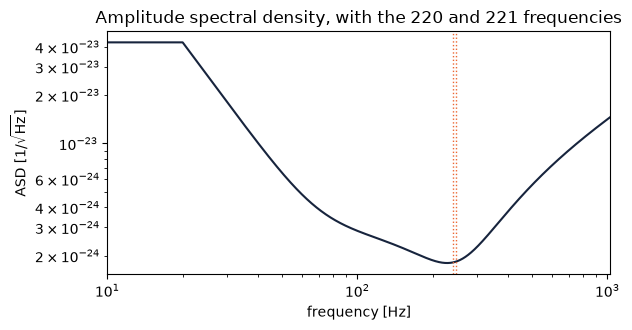

In [17]:
_f, _ = truth.remnant.qnms()
_keep = freqs >= 10
_fig, _ax = plt.subplots(figsize=(6.4, 3.4))
_ax.loglog(freqs[_keep], np.sqrt(psd[_keep]) * STRAIN_UNIT, color=TRUTH)
for _fi, _mode in zip(np.asarray(_f), MODES):
    _ax.axvline(_fi, color=PRIOR, linewidth=1, linestyle=":")
_ax.set(xlim=(10, 1024), xlabel="frequency [Hz]", ylabel=r"ASD [1/$\sqrt{\mathrm{Hz}}$]",
        title="Amplitude spectral density, with the 220 and 221 frequencies")
_fig.tight_layout()
_fig

Whitening by $L^{-1}$ turns the noise in each detector into independent standard normals,
so the signal can be seen against unit noise:

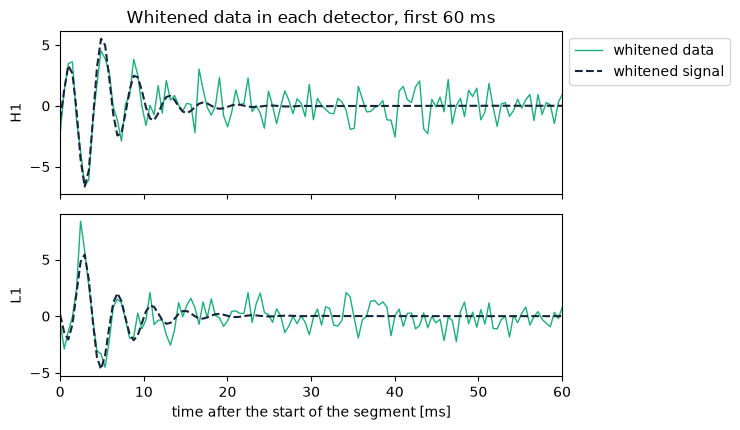

In [18]:
_t = 1e3 * np.asarray(network.detectors.t)
_wd = np.asarray(network.detectors.whiten(data.h))
_wh = np.asarray(network.detectors.whiten(network.signal(truth)))
_fig, _axes = plt.subplots(2, 1, figsize=(7.5, 4.4), sharex=True)
for _i, (_ax, _ifo) in enumerate(zip(_axes, network.ifos)):
    _ax.plot(_t, _wd[_i], color=DATA, linewidth=1, label="whitened data")
    _ax.plot(_t, _wh[_i], color=TRUTH, linestyle="--", linewidth=1.5, label="whitened signal")
    _ax.set(ylabel=_ifo, xlim=(0, 60))
_axes[0].set_title("Whitened data in each detector, first 60 ms")
_axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_axes[1].set(xlabel="time after the start of the segment [ms]")
_fig.tight_layout()
_fig

## The prior

The priors are those of ringdown's GW150914 example: $M$ uniform between 40 and
$140\,M_\odot$, $\chi$ uniform between 0 and 0.99, and an amplitude scale per mode uniform up
to `a_scale_max` $= 5\times10^{-20}$, which is 50 in our units. As in notebook 4, the
quadratures are normal with the amplitude scale as standard deviation. The prior is a
structured distribution over the nested type: the remnant fields are plain NumPyro
distributions, the quadratures are functions of the condition, and `.given` on the outer
distribution passes the condition down to `Quadratures.distribution`.

In [19]:
def per_mode(distribution):
    """Independent copies of a scalar distribution, one per mode."""
    return distribution.expand([len(MODES)]).to_event(1)

prior = KerrRingdown.distribution(
    remnant=Remnant.distribution(M=dist.Uniform(40.0, 140.0), chi=dist.Uniform(0.0, 0.99)),
    modes=Quadratures.distribution(
        ax=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
        ay=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
    ),
).given({"a_scale": float})
prior

order,"remnant.M, remnant.chi, modes.ax, modes.ay"


In [20]:
prior.graph()

Graph('Graph of StructuredDistribution[KerrRingdown]', nodes=['cond:a_scale', 'remnant.M', 'remnant.chi', 'modes.ax', 'modes.ay'], edges=[('cond:a_scale', 'modes.ax'), ('cond:a_scale', 'modes.ay')])

## The model

The model is the one of notebook 4 with the new prior and measurement process. It also
records the frequency and damping time of each mode as deterministic sites:

In [21]:
def model(data):
    a_scale = ai.sample("a_scale", per_mode(dist.Uniform(0.0, 50.0)))
    theta = ai.sample("theta", prior, a_scale=a_scale)
    ai.sample("d", network, theta, obs=data)
    f, gamma = theta.remnant.qnms()
    numpyro.deterministic("f", f)
    numpyro.deterministic("tau", 1e3 / gamma)

ai.model_graph(model, data, expand=True)

Graph('Graph of model', nodes=['a_scale', 'theta.remnant.M', 'theta.remnant.chi', 'theta.modes.ax', 'theta.modes.ay', 'd', 'f', 'tau'], edges=[('a_scale', 'theta.modes.ax'), ('a_scale', 'theta.modes.ay'), ('theta.remnant.M', 'd'), ('theta.remnant.chi', 'd'), ('theta.modes.ax', 'd'), ('theta.modes.ay', 'd'), ('theta.remnant.M', 'f'), ('theta.remnant.chi', 'f'), ('theta.remnant.M', 'tau'), ('theta.remnant.chi', 'tau')])

In [22]:
posterior = ai.infer(model, data, seed=0, num_warmup=1000, num_samples=4000, summary=False)
posterior.summary(["theta.remnant.M", "theta.remnant.chi", "f", "tau"], expand=True)

,mean,sd,5.0%,95.0%,ess,r_hat
theta.remnant.M,66.556549,10.338290,49.199802,82.523721,738.370346,1.000186
theta.remnant.chi,0.601076,0.212354,0.277426,0.913013,746.126234,1.000415
f[0],250.857822,14.923157,225.806872,272.747359,453.601667,1.000303
f[1],243.819378,14.956044,218.249213,265.288442,443.289846,1.000635
tau[0],4.097223,0.968385,2.628636,5.487866,829.999094,1.000627
tau[1],1.350595,0.327462,0.844930,1.805515,832.530545,1.000643


The posterior mean of the mass is $66.6\,M_\odot$ with a standard deviation of 10.3, and that
of the spin is 0.60 with a standard deviation of 0.21. The true values, 70 and 0.7, lie inside
the 90% intervals, 49 to 83 and 0.28 to 0.91. The fundamental mode has $f = 250.9\pm14.9$ Hz
and $\tau = 4.1\pm1.0$ ms, against true values of 246.9 Hz and 4.24 ms, and the overtone has
$\tau = 1.35\pm0.33$ ms against 1.40 ms. The run has 2 divergent transitions in 4000 draws.

For the real GW150914, in the noisier detectors of the first observing run, ringdown's
documentation reports $M = 72.1\pm8.2\,M_\odot$ and $\chi = 0.68\pm0.17$.

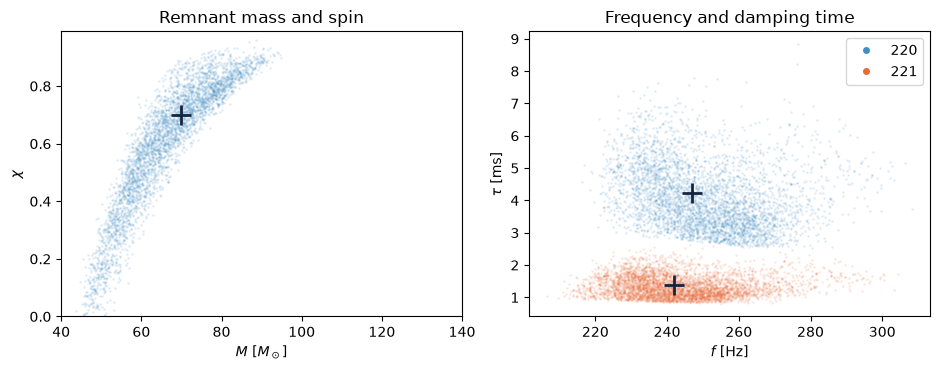

In [23]:
_theta = posterior.theta.theta
_M, _chi = np.asarray(_theta.remnant.M).ravel(), np.asarray(_theta.remnant.chi).ravel()
_f, _tau = np.asarray(posterior.extras["f"]), np.asarray(posterior.extras["tau"])
_f_true, _gamma_true = truth.remnant.qnms()

_fig, _axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
_axes[0].plot(_M, _chi, ".", color=POSTERIOR, alpha=0.1, markersize=2)
_axes[0].plot(float(truth.remnant.M), float(truth.remnant.chi), "+", color=TRUTH,
              markersize=14, mew=2)
_axes[0].set(xlim=(40, 140), ylim=(0, 0.99), xlabel=r"$M\ [M_\odot]$", ylabel=r"$\chi$",
             title="Remnant mass and spin")
for _i, (_mode, _color) in enumerate(zip(MODES, [POSTERIOR, PRIOR])):
    _axes[1].plot(_f[..., _i].ravel(), _tau[..., _i].ravel(), ".", color=_color, alpha=0.1,
                  markersize=2)
    _axes[1].plot([], [], ".", color=_color, markersize=8, label=_mode)
    _axes[1].plot(float(_f_true[_i]), 1e3 / float(_gamma_true[_i]), "+", color=TRUTH,
                  markersize=14, mew=2)
_axes[1].set(xlabel="$f$ [Hz]", ylabel=r"$\tau$ [ms]", title="Frequency and damping time")
_axes[1].legend(loc="upper right")
_fig.tight_layout()
_fig

In the left panel, the mass and spin are correlated along a curve on which the frequency of
the fundamental mode changes little: a heavier black hole that spins faster rings at about
the same frequency. The data constrain that frequency better than they constrain $M$ or
$\chi$ alone.

The fit can be extended in the ways ringdown's can, each of which is a change to one of the
objects above: more modes need more rows in `kerr_qnms` and more entries in `MODES`, fractional deviations $\delta f$ and
$\delta\gamma$ from the Kerr values add fields to `Remnant` and two factors in `polarizations`,
and a free inclination replaces the field `cosi` with a parameter.